# Task 2 – Predictive modeling of customer bookings

Goal: predict `booking_complete` and find out which variables drive it.

## 1. Load and clean the data

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

df = pd.read_csv("data/customer_booking.csv", encoding="ISO-8859-1")
print("Rows before:", len(df))
df = df.drop_duplicates()          # 719 exact duplicate rows
print("Rows after removing duplicates:", len(df))

df["flight_day"] = df["flight_day"].map({"Mon":1,"Tue":2,"Wed":3,"Thu":4,"Fri":5,"Sat":6,"Sun":7})
print("Share of completed bookings:", round(df["booking_complete"].mean(), 3))

Rows before: 50000
Rows after removing duplicates: 49281
Share of completed bookings: 0.15


Only about 15% of customers complete a booking, so the target is **imbalanced**. Accuracy alone will be misleading: a model that always says "no booking" would already be 85% accurate.

## 2. Explore: which groups book more often?

In [2]:
for col in ["sales_channel", "trip_type", "wants_extra_baggage", "wants_preferred_seat", "wants_in_flight_meals"]:
    print(df.groupby(col)["booking_complete"].agg(completion_rate="mean", bookings="size").round(3), "\n")

origin = df.groupby("booking_origin")["booking_complete"].agg(completion_rate="mean", bookings="size")
origin[origin["bookings"] > 500].sort_values("completion_rate", ascending=False).round(3)

               completion_rate  bookings
sales_channel                           
Internet                 0.155     43917
Mobile                   0.110      5364 

            completion_rate  bookings
trip_type                            
CircleTrip            0.043       116
OneWay                0.052       386
RoundTrip             0.151     48779 

                     completion_rate  bookings
wants_extra_baggage                           
0                              0.115     16350
1                              0.167     32931 

                      completion_rate  bookings
wants_preferred_seat                           
0                               0.138     34712
1                               0.178     14569 

                       completion_rate  bookings
wants_in_flight_meals                           
0                                0.142     28256
1                                0.161     21025 



,completion_rate,bookings
booking_origin,,
Malaysia,0.345,7055
Singapore,0.285,1034
Indonesia,0.263,2317
Thailand,0.233,1993
China,0.208,3284
Japan,0.124,3819
Taiwan,0.108,2042
South Korea,0.102,4502
India,0.102,1258


## 3. Prepare features

- `sales_channel`, `trip_type`: one-hot encoded (few categories)
- `route` (799 values) and `booking_origin` (104 values): target encoded, i.e. each category is replaced by its average completion rate, learned on the training data only
- Everything else is already numeric

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from sklearn.pipeline import Pipeline

X = df.drop(columns="booking_complete")
y = df["booking_complete"]

pre = ColumnTransformer([
    ("onehot", OneHotEncoder(handle_unknown="ignore"), ["sales_channel", "trip_type"]),
    ("target", TargetEncoder(random_state=42), ["route", "booking_origin"]),
], remainder="passthrough", verbose_feature_names_out=False)

model = Pipeline([
    ("pre", pre),
    ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                  class_weight="balanced", random_state=42, n_jobs=-1)),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

## 4. Train and evaluate

`class_weight="balanced"` makes the forest pay more attention to the rare "booked" class.

In [4]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model.fit(X_train, y_train)
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred, digits=3))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))
print("ROC AUC:", round(roc_auc_score(y_test, proba), 3))

              precision    recall  f1-score   support

           0      0.926     0.771     0.841      8379
           1      0.333     0.648     0.440      1478

    accuracy                          0.753      9857
   macro avg      0.629     0.710     0.641      9857
weighted avg      0.837     0.753     0.781      9857

Confusion matrix:
 [[6462 1917]
 [ 520  958]]
ROC AUC: 0.788


In [5]:
cv = cross_validate(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
pd.DataFrame({k.replace("test_", ""): [v.mean().round(3), v.std().round(3)]
              for k, v in cv.items() if k.startswith("test_")}, index=["mean", "std"])

,accuracy,precision,recall,f1,roc_auc
mean,0.754,0.337,0.658,0.445,0.795
std,0.004,0.005,0.007,0.005,0.003


## 5. Which variables contribute most?

Permutation importance: shuffle one column at a time in the test set and measure how much ROC AUC drops.

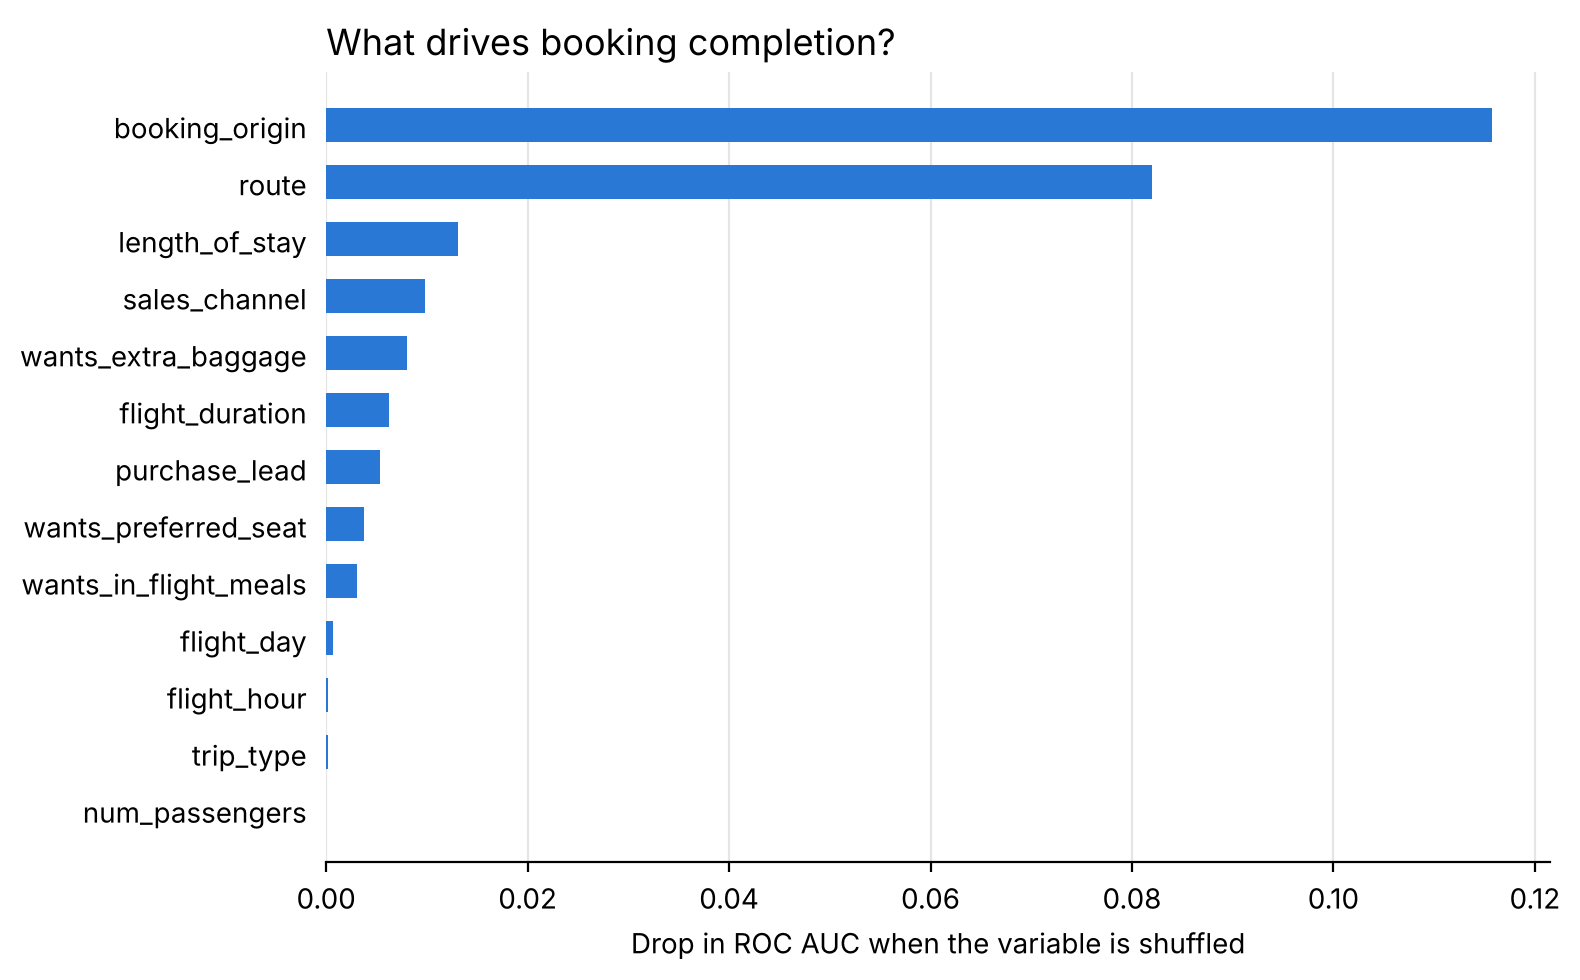

In [6]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color="#2a78d6", height=0.6)
ax.set_title("What drives booking completion?", loc="left", fontsize=13)
ax.set_xlabel("Drop in ROC AUC when the variable is shuffled")
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.tick_params(left=False); ax.grid(axis="x", color="#e5e5e5"); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=200); plt.show()

## 6. Summary

- The model separates bookers from non-bookers reasonably well (ROC AUC about 0.79) but is far from perfect.
- It finds about two thirds of real bookers (recall about 0.65), but only one in three customers it flags actually books (precision about 0.33).
- `booking_origin` and `route` carry most of the predictive power; trip details such as flight hour, day and passenger count add almost nothing.
- Next step: add customer-level features (past bookings, loyalty status, price shown, searches before booking).